In [23]:
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [5]:
search_lc=lk.search_lightcurve('TIC 100100827',mission="TESS", author="SPOC")
search_lc

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 02,2018,SPOC,120,100100827,0.0
1,TESS Sector 03,2018,SPOC,120,100100827,0.0
2,TESS Sector 29,2020,SPOC,20,100100827,0.0
3,TESS Sector 30,2020,SPOC,20,100100827,0.0
4,TESS Sector 29,2020,SPOC,120,100100827,0.0
5,TESS Sector 30,2020,SPOC,120,100100827,0.0
6,TESS Sector 69,2023,SPOC,20,100100827,0.0
7,TESS Sector 69,2023,SPOC,120,100100827,0.0
8,TESS Sector 96,2025,SPOC,20,100100827,0.0


In [17]:
lc_collection=search_lc[-7:].download_all()
cleaned_lc=[
    lc.remove_nans().normalize().flatten(window_length=201)
    for lc in lc_collection
]

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

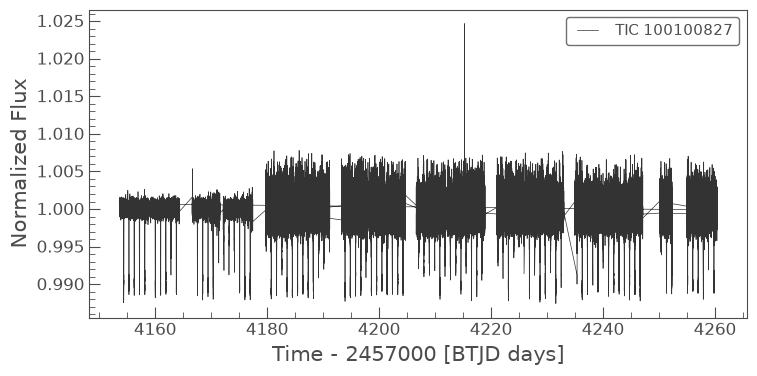

In [19]:
stitched_lc=lk.LightCurveCollection(cleaned_lc).stitch()
stitched_lc.plot()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

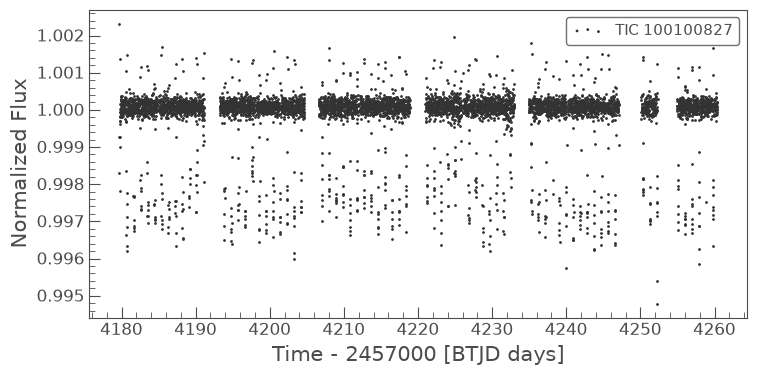

In [22]:
binned_lc= stitched_lc.bin(time_bin_size=15/24/60)
binned_lc.scatter()

<Axes: xlabel='Period [$\\mathrm{d}$]', ylabel='BLS Power'>

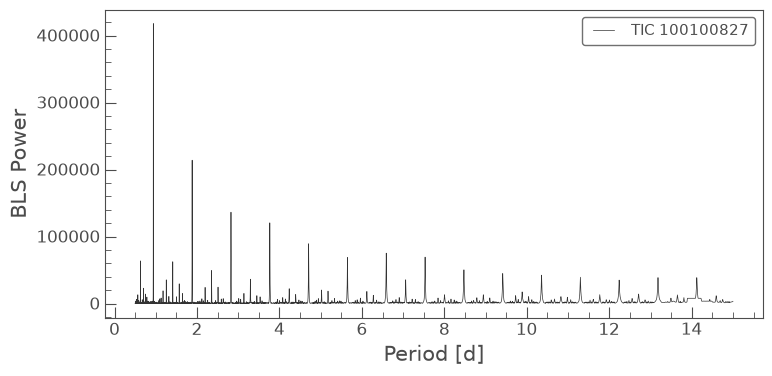

In [25]:
durations=np.linspace(0.05,0.2,10)

periodogram = stitched_lc.to_periodogram(method="bls",minimum_period=0.5,maximum_period=15,duration=durations,frequency_factor=5)
periodogram.plot()

In [26]:
best_period= periodogram.period_at_max_power
best_t0=periodogram.transit_time_at_max_power
best_duration=periodogram.duration_at_max_power
best_depth=periodogram.depth_at_max_power

print(f"Detected Orbital Period:  {best_period.value:.5f} days")
print(f"Transit Epoch (T0):       {best_t0.value:.5f} BTJD")
print(f"Transit Duration:         {best_duration.value * 24:.2f} hours")
print(f"Transit Depth:            {best_depth.value * 100:.3f}%")

Detected Orbital Period:  0.94143 days
Transit Epoch (T0):       4154.33871 BTJD
Transit Duration:         2.04 hours
Transit Depth:            0.479%


In [ ]:
#This folding shows a wierd half dip

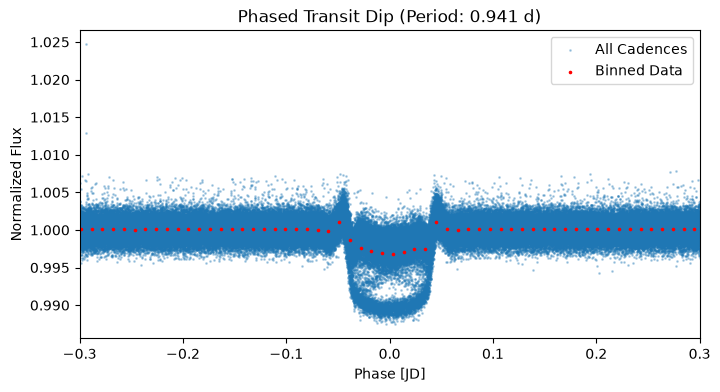

In [28]:
folded_lc=stitched_lc.fold(period=best_period, epoch_time=best_t0)
binned_folded = folded_lc.bin(time_bin_size=15/60/24) 

fig, ax = plt.subplots(figsize=(8, 4))
folded_lc.scatter(ax=ax, alpha=0.3, label="All Cadences")
binned_folded.scatter(ax=ax, color="red", s=10, label="Binned Data")
ax.set_xlim(-0.3, 0.3)
plt.title(f"Phased Transit Dip (Period: {best_period.value:.3f} d)")
plt.legend()
plt.show()